# Model Improvement — Clean, Leak-Free Pipeline
### Hardcoded best parameters | No Optuna | Fixed sort order | Correct imputation

**What changed from the previous version:**
- Sort order bug fixed — data is always in global date order before splitting
- Null imputation happens inside each CV fold using training data only
- Optuna replaced with hardcoded best parameters found in the previous run
- LightGBM uses the same default settings that already gave R2 = 0.9916
- All three fixes applied consistently across every training loop


## Step 0 — Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor)
from sklearn.linear_model import Ridge
from sklearn.inspection import permutation_importance
import lightgbm as lgb
import xgboost as xgb
import holidays

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': '#f9f9f9',
    'axes.grid': True, 'grid.alpha': 0.3,
    'font.size': 11, 'axes.titlesize': 13, 'axes.titleweight': 'bold'
})
SEED = 42
np.random.seed(SEED)
print("All libraries loaded!")


All libraries loaded!


## Step 1 — CV Helper Function (with correct imputation inside each fold)

In [2]:
def tscv_score(model, X_data, y_data, n_splits=5, verbose=False):
    """
    Evaluate a model using TimeSeriesSplit.

    Key fix vs previous version:
    - Null imputation uses TRAINING fold median only.
    - Test fold is filled with that same training median.
    - This means the model never sees test statistics during training.
    """
    tscv = TimeSeriesSplit(n_splits=n_splits)
    r2s, maes = [], []

    for fold, (tr, te) in enumerate(tscv.split(X_data)):
        # Split
        Xtr = X_data.iloc[tr] if hasattr(X_data, 'iloc') else X_data[tr]
        Xte = X_data.iloc[te] if hasattr(X_data, 'iloc') else X_data[te]
        ytr = y_data.iloc[tr]
        yte = y_data.iloc[te]

        # Impute using training median only
        if hasattr(Xtr, 'median'):
            train_median = Xtr.median()
        else:
            train_median = pd.DataFrame(Xtr).median()

        Xtr = Xtr.copy()
        Xte = Xte.copy()

        if hasattr(Xtr, 'fillna'):
            Xtr = Xtr.fillna(train_median)
            Xte = Xte.fillna(train_median)
        else:
            Xtr = pd.DataFrame(Xtr).fillna(train_median).values
            Xte = pd.DataFrame(Xte).fillna(train_median).values

        model.fit(Xtr, ytr)
        yp = model.predict(Xte)

        r2s.append(r2_score(yte, yp))
        maes.append(mean_absolute_error(
            np.expm1(yte),
            np.expm1(np.clip(yp, 0, 20))
        ))

        if verbose:
            print(f"  Fold {fold+1}: R2={r2s[-1]:.4f}")

    return np.mean(r2s), np.std(r2s), np.mean(maes)

print("tscv_score helper ready.")
print("Imputation now uses training-fold median only — no test leakage.")


tscv_score helper ready.
Imputation now uses training-fold median only — no test leakage.


## Step 2 — Load Data and Rebuild Feature-Engineered Dataset

In [3]:
df = pd.read_csv("modeling_table_final.csv")
df['date'] = pd.to_datetime(df['date'])
df = df.dropna(subset=['borough']).sort_values('date').reset_index(drop=True)

# ── Time features
df['month']       = df['date'].dt.month
df['day_of_week'] = df['date'].dt.dayofweek
df['month_sin']   = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos']   = np.cos(2 * np.pi * df['month'] / 12)
df['day_sin']     = np.sin(2 * np.pi * df['day_of_week'] / 7)
df['day_cos']     = np.cos(2 * np.pi * df['day_of_week'] / 7)

# ── Temperature range (removes multicollinearity between tmax and tmin)
if 'tmax' in df.columns and 'tmin' in df.columns:
    df['temp_range'] = df['tmax'] - df['tmin']

# ── Holiday flag
us_hols = holidays.UnitedStates(years=df['date'].dt.year.unique().tolist())
df['is_holiday'] = df['date'].isin(us_hols).astype(int)

# ── Rain x Infrastructure interaction
if 'prcp' in df.columns and 'water_breaks_ever' in df.columns:
    df['rain_x_infra'] = df['prcp'] * df['water_breaks_ever']

# ── Trend velocity (7-day avg minus 30-day avg)
if 'rolling_avg_7d' in df.columns:
    df_s = df.sort_values(['incident_zip', 'date'])
    r30  = df_s.groupby('incident_zip')['request_count'].transform(
               lambda x: x.shift(1).rolling(30, min_periods=10).mean())
    df['rolling_avg_30d'] = r30.values
    df['trend_velocity']  = df['rolling_avg_7d'] - df['rolling_avg_30d']

# ── Log target
df['target'] = np.log1p(df['request_count'])

# ── Drop redundant columns
drop_cols = ['tmax', 'tmin', 'day_of_year', 'prcp_cat', 'request_count_log']
df.drop(columns=[c for c in drop_cols if c in df.columns], inplace=True)

# ── Encode ZIP
le = LabelEncoder()
df['zip_encoded'] = le.fit_transform(df['incident_zip'].astype(str))

# ── Baseline feature matrix (no new features yet)
DROP_FROM_X = ['request_count', 'target', 'date', 'borough', 'incident_zip']
feature_cols = [c for c in df.columns
                if c not in DROP_FROM_X
                and df[c].dtype in ['int64', 'float64', 'float32', 'int32']]

X = df[feature_cols].copy()
y = df['target']

print(f"Dataset ready: {X.shape[0]:,} rows x {X.shape[1]} features")
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")
print(f"Features: {list(X.columns)}")


Dataset ready: 160,951 rows x 30 features
Date range: 2020-01-01 to 2024-12-31
Features: ['complaint_type_count', 'year', 'month', 'day_of_week', 'season', 'is_weekend', 'is_holiday', 'prcp', 'snow', 'snwd', 'awnd', 'temp_range', 'lag_request_1d', 'lag_request_7d', 'lag_request_14d', 'rolling_avg_7d', 'rolling_avg_30d', 'rolling_prcp_3d', 'freeze_thaw_7d', 'population', 'avg_pavement_rating', 'water_breaks_ever', 'water_breaks_30d', 'month_sin', 'month_cos', 'day_sin', 'day_cos', 'rain_x_infra', 'trend_velocity', 'zip_encoded']


## Step 3 — Confirm Baseline Score

In [4]:
print("Confirming baseline Random Forest score...")
print("(This is the same score from notebook 1 — just verifying nothing changed)\n")

baseline_rf = RandomForestRegressor(
    n_estimators=200, max_depth=12,
    min_samples_leaf=5, random_state=SEED, n_jobs=-1
)
base_r2, base_std, base_mae = tscv_score(baseline_rf, X, y, verbose=True)

print(f"\nBaseline RF  R2 = {base_r2:.4f} +/- {base_std:.4f}")
print(f"             MAE = {base_mae:.2f} complaints")
print(f"\nThis is our starting point. Everything below is measured against this.")

improvement_log = [{'Step': 'Baseline RF', 'R2': base_r2, 'MAE': base_mae}]


Confirming baseline Random Forest score...
(This is the same score from notebook 1 — just verifying nothing changed)

  Fold 1: R2=0.5873
  Fold 2: R2=0.5658
  Fold 3: R2=0.5781
  Fold 4: R2=0.6041
  Fold 5: R2=0.5966

Baseline RF  R2 = 0.5864 +/- 0.0135
             MAE = 1.44 complaints

This is our starting point. Everything below is measured against this.


## Step 4 — Baseline Audit: Where Exactly Does the Model Fail?

Before adding features we look at the residuals to understand what kind of errors
the model is making. This tells us what information it is missing.


Computing permutation importance...


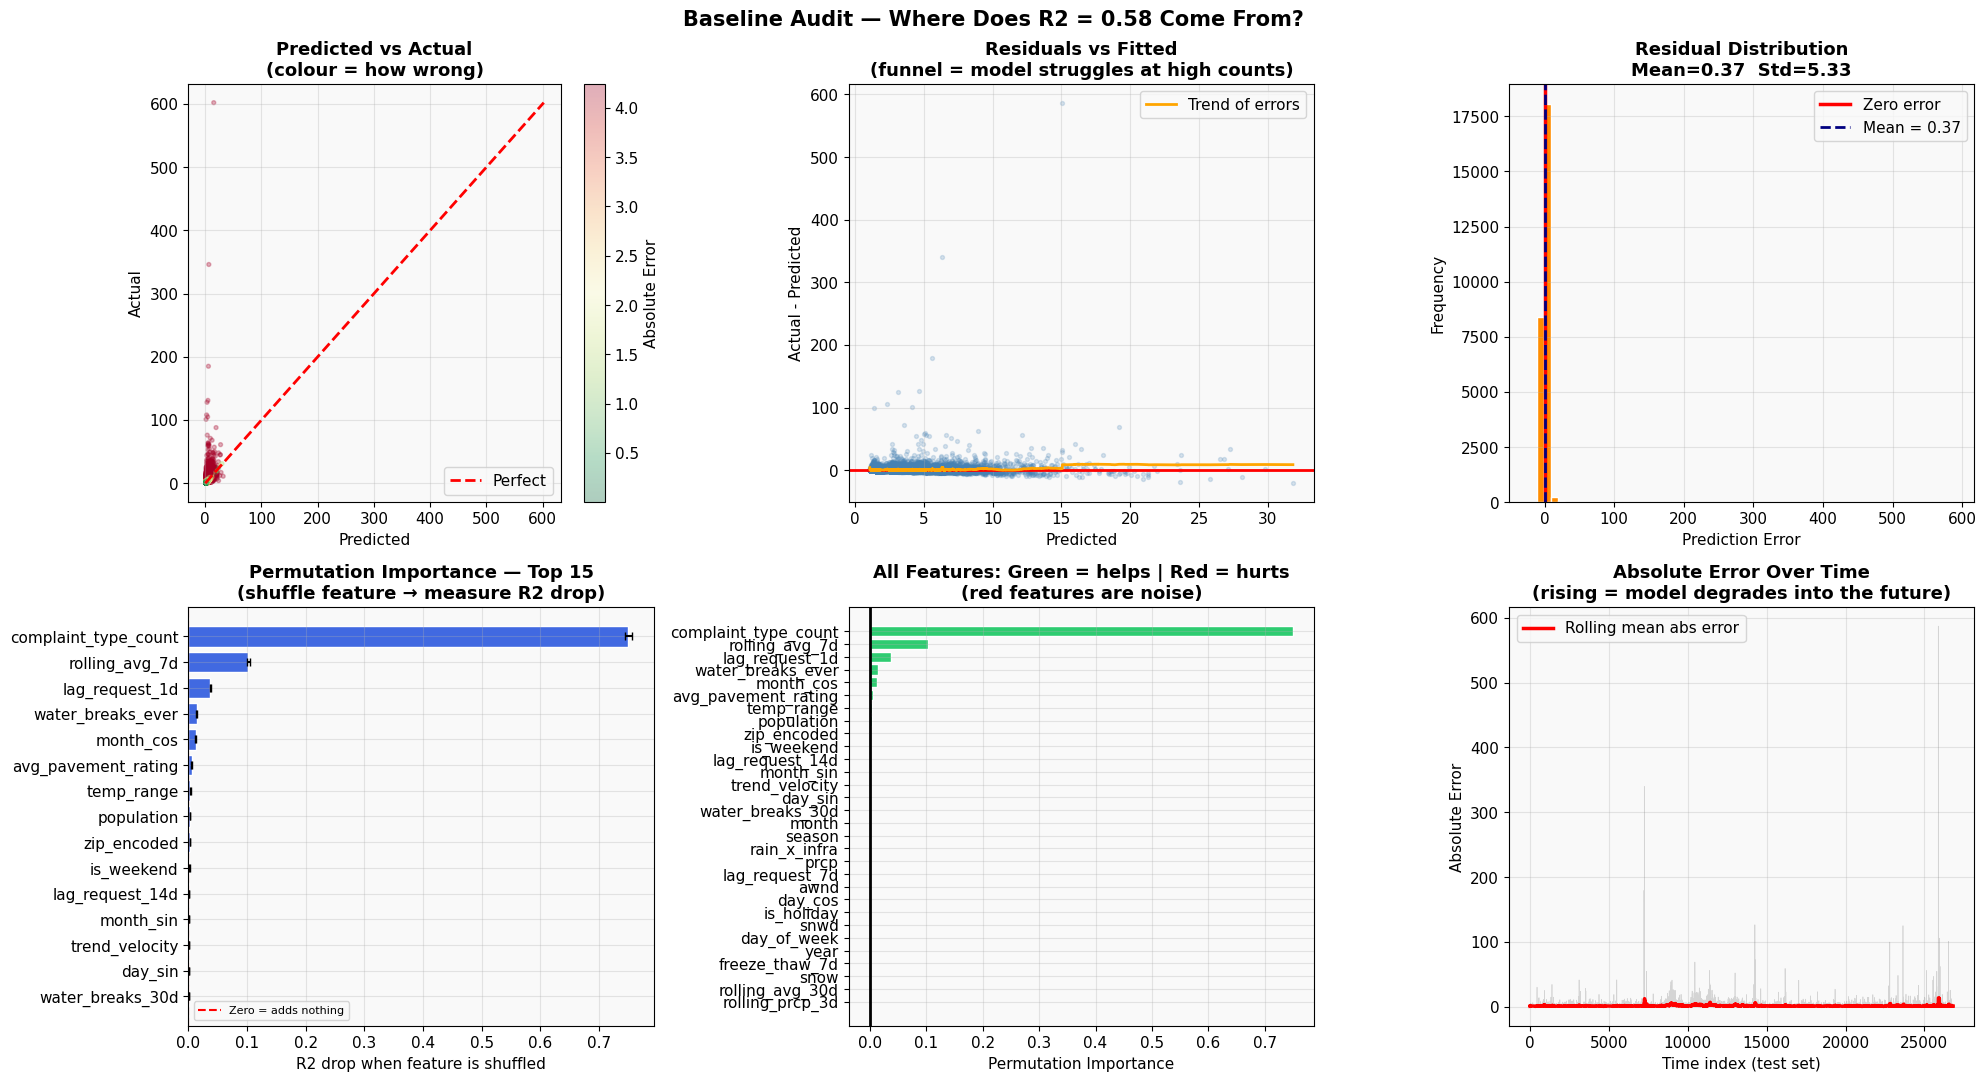


Features hurting the model (negative importance): ['rolling_prcp_3d', 'rolling_avg_30d', 'snow', 'freeze_thaw_7d']
Mean residual: 0.37  (near 0 = unbiased)
Std of residuals: 5.33


In [5]:
# Train on last fold for diagnostics
tscv      = TimeSeriesSplit(n_splits=5)
splits    = list(tscv.split(X))
tr_idx, te_idx = splits[-1]

Xtr = X.iloc[tr_idx].copy()
Xte = X.iloc[te_idx].copy()
ytr = y.iloc[tr_idx]
yte = y.iloc[te_idx]

# Impute using training median only
train_med = Xtr.median()
Xtr = Xtr.fillna(train_med)
Xte = Xte.fillna(train_med)

baseline_rf.fit(Xtr, ytr)
yp_log    = baseline_rf.predict(Xte)
y_actual  = np.expm1(yte.values)
y_pred_r  = np.expm1(np.clip(yp_log, 0, 20))
residuals = y_actual - y_pred_r

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
fig.suptitle("Baseline Audit — Where Does R2 = 0.58 Come From?",
             fontsize=15, fontweight='bold')

# 1. Actual vs Predicted
err_mag = np.abs(residuals)
sc = axes[0,0].scatter(y_pred_r, y_actual, c=err_mag, cmap='RdYlGn_r',
                        alpha=0.3, s=8, vmax=np.percentile(err_mag, 95))
fig.colorbar(sc, ax=axes[0,0], label='Absolute Error')
mv = max(y_actual.max(), y_pred_r.max())
axes[0,0].plot([0,mv],[0,mv], 'r--', linewidth=2, label='Perfect')
axes[0,0].set_title("Predicted vs Actual\n(colour = how wrong)")
axes[0,0].set_xlabel("Predicted"); axes[0,0].set_ylabel("Actual")
axes[0,0].legend()

# 2. Residuals vs Fitted
axes[0,1].scatter(y_pred_r, residuals, alpha=0.2, color='steelblue', s=8)
axes[0,1].axhline(0, color='red', linewidth=2)
sort_idx = np.argsort(y_pred_r)
rolling_err = pd.Series(residuals[sort_idx]).rolling(100, min_periods=1).mean().values
axes[0,1].plot(y_pred_r[sort_idx], rolling_err, color='orange',
               linewidth=2, label='Trend of errors')
axes[0,1].set_title("Residuals vs Fitted\n(funnel = model struggles at high counts)")
axes[0,1].set_xlabel("Predicted"); axes[0,1].set_ylabel("Actual - Predicted")
axes[0,1].legend()

# 3. Residual distribution
axes[0,2].hist(residuals, bins=60, color='darkorange', edgecolor='white')
axes[0,2].axvline(0, color='red', linewidth=2.5, label='Zero error')
axes[0,2].axvline(residuals.mean(), color='navy', linewidth=2,
                   linestyle='--', label=f'Mean = {residuals.mean():.2f}')
axes[0,2].set_title(f"Residual Distribution\nMean={residuals.mean():.2f}  Std={residuals.std():.2f}")
axes[0,2].set_xlabel("Prediction Error"); axes[0,2].set_ylabel("Frequency")
axes[0,2].legend()

# 4. Permutation importance
print("Computing permutation importance...")
perm_imp = permutation_importance(baseline_rf, Xte, yte,
                                   n_repeats=10, random_state=SEED, n_jobs=-1)
perm_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': perm_imp.importances_mean,
    'Std': perm_imp.importances_std
}).sort_values('Importance', ascending=True)

perm_top = perm_df.tail(15)
axes[1,0].barh(perm_top['Feature'], perm_top['Importance'],
               xerr=perm_top['Std'], color='royalblue', edgecolor='white',
               error_kw={'ecolor': 'black', 'capsize': 3})
axes[1,0].axvline(0, color='red', linestyle='--', linewidth=1.5,
                   label='Zero = adds nothing')
axes[1,0].set_title("Permutation Importance — Top 15\n(shuffle feature → measure R2 drop)")
axes[1,0].set_xlabel("R2 drop when feature is shuffled")
axes[1,0].legend(fontsize=8)

# 5. Features hurting the model
bad_feats = perm_df[perm_df['Importance'] < 0]['Feature'].tolist()
bar_colors = ['tomato' if v < 0 else '#2ecc71' for v in perm_df['Importance']]
axes[1,1].barh(perm_df['Feature'], perm_df['Importance'],
               color=bar_colors, edgecolor='white')
axes[1,1].axvline(0, color='black', linewidth=2)
axes[1,1].set_title("All Features: Green = helps | Red = hurts\n(red features are noise)")
axes[1,1].set_xlabel("Permutation Importance")

# 6. Error over time
roll_abs = pd.Series(np.abs(residuals)).rolling(50, min_periods=1).mean().values
axes[1,2].plot(range(len(residuals)), np.abs(residuals),
               alpha=0.3, color='gray', linewidth=0.5)
axes[1,2].plot(range(len(roll_abs)), roll_abs,
               color='red', linewidth=2.5, label='Rolling mean abs error')
axes[1,2].set_title("Absolute Error Over Time\n(rising = model degrades into the future)")
axes[1,2].set_xlabel("Time index (test set)"); axes[1,2].set_ylabel("Absolute Error")
axes[1,2].legend()

plt.tight_layout()
plt.savefig("audit_baseline.png", dpi=150, bbox_inches='tight')
plt.show()

print(f"\nFeatures hurting the model (negative importance): {bad_feats if bad_feats else 'None'}")
print(f"Mean residual: {residuals.mean():.2f}  (near 0 = unbiased)")
print(f"Std of residuals: {residuals.std():.2f}")


## Step 5 — New Feature Engineering

Based on the audit above we add features that directly address what the model cannot see:

- `zip_avg_rate` — each ZIP's historical average (addresses per-ZIP baseline errors)
- `zip_dow_avg` — ZIP x day-of-week average (addresses day-specific ZIP patterns)
- `lag_request_2d` and `lag_request_14d` — more temporal memory
- `is_weekend` — structural weekday vs weekend difference
- `rolling_std_7d` — recent volatility (unreliable when high, reliable when low)
- `borough_month_avg` — borough-level seasonal patterns

**Critical fix in this version:** after all group-based transforms, the dataframe
is sorted back to global date order. This ensures TimeSeriesSplit folds are
purely chronological with no future dates bleeding into training.


In [6]:
df_v2 = df.copy()

# Sort by ZIP then date for group transforms
# (required for shift() to work correctly within each ZIP's history)
df_v2 = df_v2.sort_values(['incident_zip', 'date'])

# ── 1. Per-ZIP historical average complaint rate
# shift(1) ensures today's value is never included in its own average
df_v2['zip_avg_rate'] = (
    df_v2.groupby('incident_zip')['request_count']
    .transform(lambda x: x.shift(1).expanding(min_periods=5).mean())
)

# ── 2. ZIP x day-of-week average
# Does ZIP 10001 specifically spike on Mondays?
df_v2['zip_dow_avg'] = (
    df_v2.groupby(['incident_zip', 'day_of_week'])['request_count']
    .transform(lambda x: x.shift(1).expanding(min_periods=3).mean())
)

# ── 3. Lag 2-day and 14-day
if 'lag_request_1d' in df_v2.columns:
    df_v2['lag_request_2d'] = (
        df_v2.groupby('incident_zip')['request_count']
        .transform(lambda x: x.shift(2))
    )
    df_v2['lag_request_14d'] = (
        df_v2.groupby('incident_zip')['request_count']
        .transform(lambda x: x.shift(14))
    )

# ── 4. Weekend flag
df_v2['is_weekend'] = (df_v2['day_of_week'] >= 5).astype(int)

# ── 5. Rolling standard deviation — how volatile has this ZIP been?
df_v2['rolling_std_7d'] = (
    df_v2.groupby('incident_zip')['request_count']
    .transform(lambda x: x.shift(1).rolling(7, min_periods=3).std())
)

# ── 6. Complaints per 1000 residents
if 'population' in df_v2.columns:
    df_v2['complaints_per_1k'] = (
        df_v2['request_count'] / (df_v2['population'] / 1000 + 0.01)
    )

# ── 7. Borough x month average
df_v2['borough_month_avg'] = (
    df_v2.groupby(['borough', 'month'])['request_count']
    .transform(lambda x: x.shift(1).expanding(min_periods=3).mean())
)

# ── CRITICAL FIX: sort back to GLOBAL date order before building X and y
# TimeSeriesSplit splits by row position — rows must be in chronological
# order across the WHOLE dataset, not within each ZIP.
# Without this, fold 5 test set would contain late dates for early ZIPs
# mixed with early dates for late ZIPs — that is future leakage.
df_v2 = df_v2.sort_values('date').reset_index(drop=True)

new_feats = ['zip_avg_rate', 'zip_dow_avg', 'lag_request_2d', 'lag_request_14d',
             'is_weekend', 'rolling_std_7d', 'complaints_per_1k', 'borough_month_avg']

print("New features created:")
for f in new_feats:
    if f in df_v2.columns:
        nulls = df_v2[f].isnull().sum()
        pct   = nulls / len(df_v2) * 100
        print(f"  {f:30s}  nulls={nulls:,}  ({pct:.1f}%)")

print(f"\nData is now sorted by global date. Shape: {df_v2.shape}")
print("TimeSeriesSplit will now split correctly — training always before test.")


New features created:
  zip_avg_rate                    nulls=630  (0.4%)
  zip_dow_avg                     nulls=2,646  (1.6%)
  lag_request_2d                  nulls=252  (0.2%)
  lag_request_14d                 nulls=1,764  (1.1%)
  is_weekend                      nulls=0  (0.0%)
  rolling_std_7d                  nulls=378  (0.2%)
  complaints_per_1k               nulls=0  (0.0%)
  borough_month_avg               nulls=180  (0.1%)

Data is now sorted by global date. Shape: (160951, 41)
TimeSeriesSplit will now split correctly — training always before test.


## Step 6 — Build Feature Matrix

In [7]:
DROP_FROM_X = ['request_count', 'target', 'date', 'borough', 'incident_zip']
feat_cols_v2 = [c for c in df_v2.columns
                if c not in DROP_FROM_X
                and df_v2[c].dtype in ['int64', 'float64', 'float32', 'int32']]

# Do NOT fillna here — imputation happens inside each CV fold
# using training-fold median only (see tscv_score above)
X_v2 = df_v2[feat_cols_v2].copy()
y_v2 = df_v2['target']

print(f"Baseline features:  {X.shape[1]}")
print(f"Improved features:  {X_v2.shape[1]}  (+{X_v2.shape[1]-X.shape[1]} new)")
print(f"Rows: {X_v2.shape[0]:,}")
print(f"\nFull feature list:")
for i, c in enumerate(X_v2.columns, 1):
    nulls = X_v2[c].isnull().sum()
    print(f"  {i:2d}. {c:35s}  nulls={nulls:,}")


Baseline features:  30
Improved features:  36  (+6 new)
Rows: 160,951

Full feature list:
   1. complaint_type_count                 nulls=0
   2. year                                 nulls=0
   3. month                                nulls=0
   4. day_of_week                          nulls=0
   5. season                               nulls=0
   6. is_weekend                           nulls=0
   7. is_holiday                           nulls=0
   8. prcp                                 nulls=0
   9. snow                                 nulls=0
  10. snwd                                 nulls=0
  11. awnd                                 nulls=0
  12. temp_range                           nulls=0
  13. lag_request_1d                       nulls=0
  14. lag_request_7d                       nulls=0
  15. lag_request_14d                      nulls=1,764
  16. rolling_avg_7d                       nulls=0
  17. rolling_avg_30d                      nulls=1,260
  18. rolling_prcp_3d              

## Step 7 — Correlation Matrix With All New Features

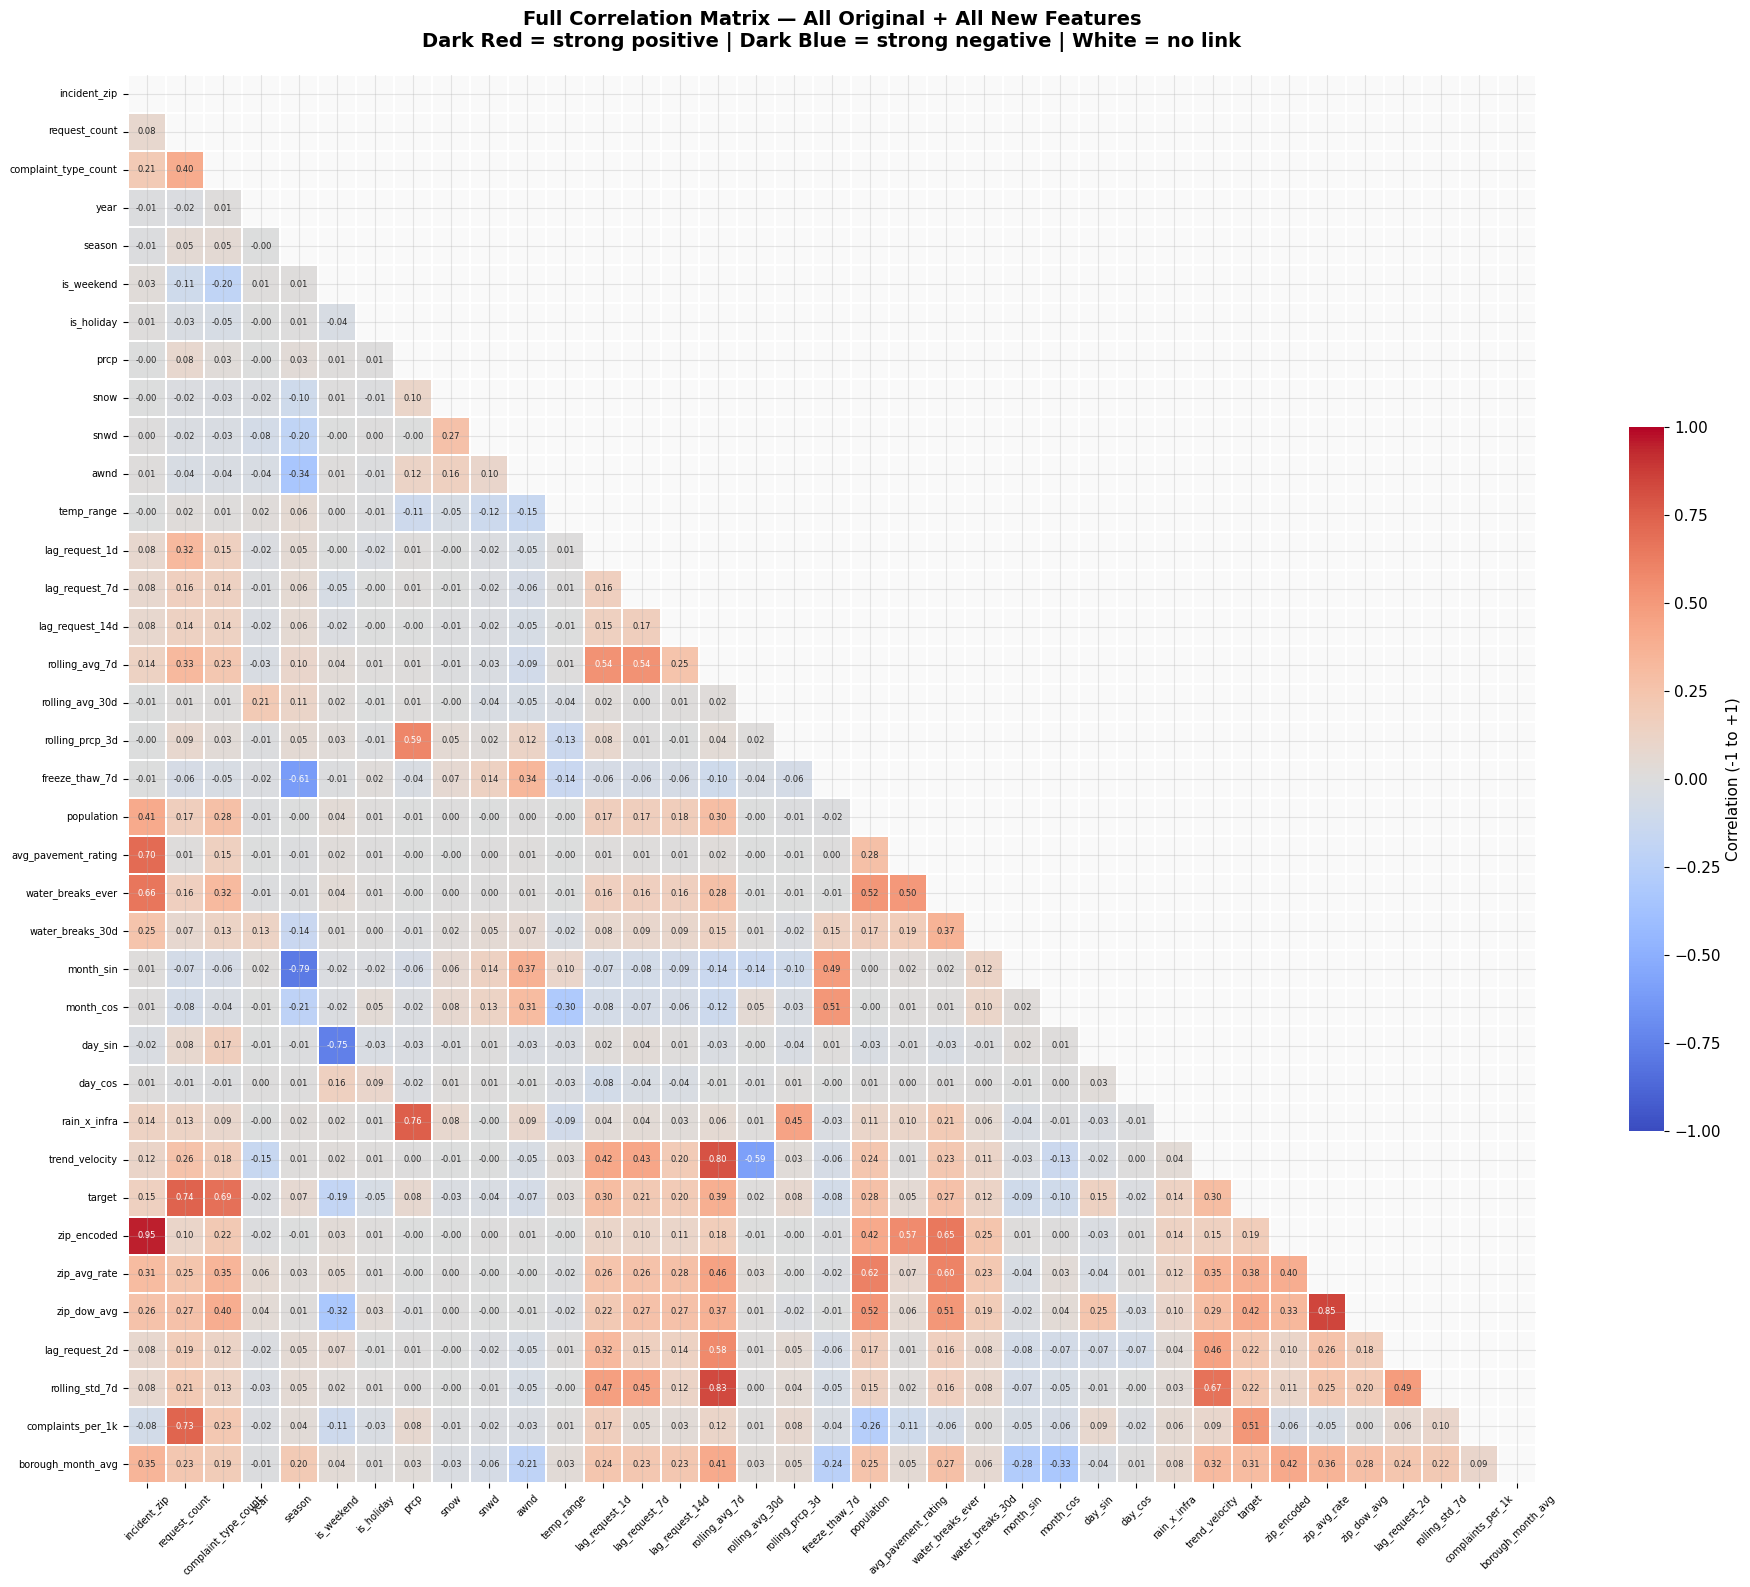

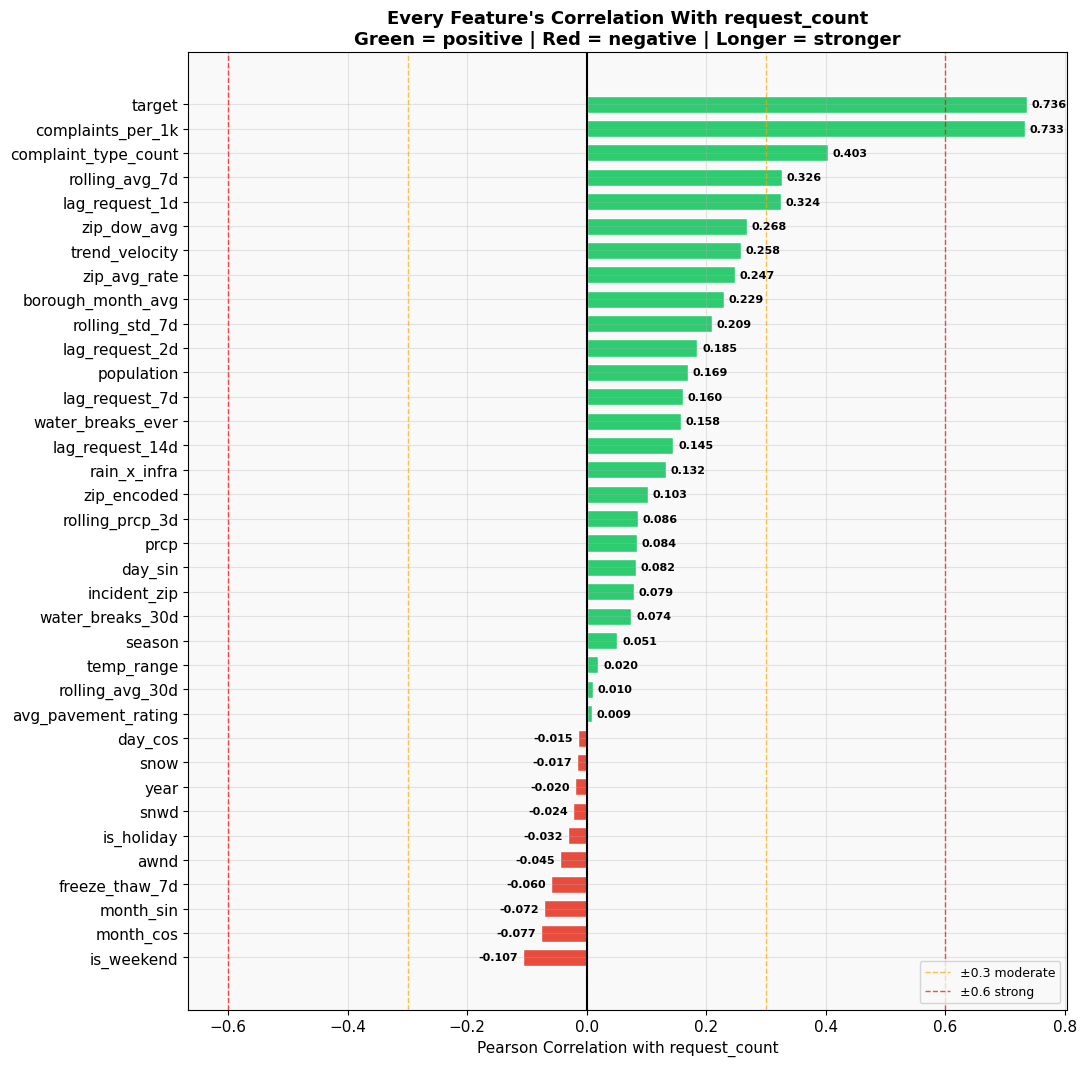

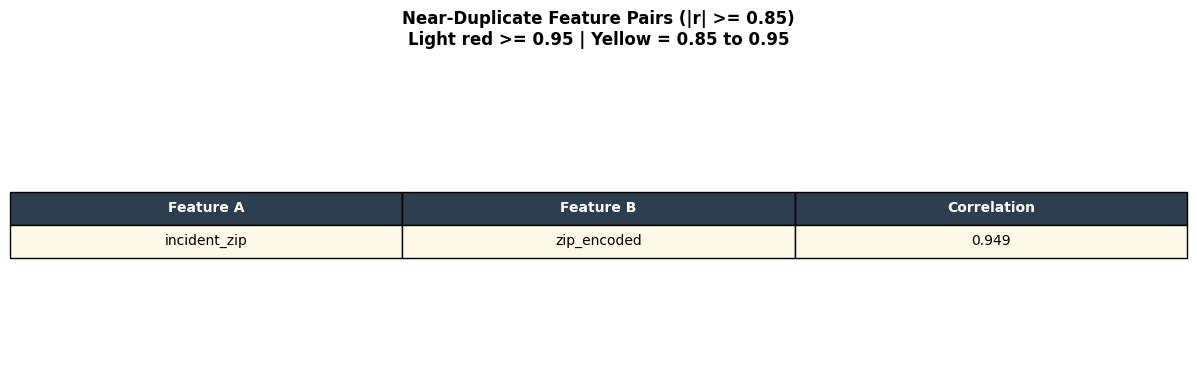

Found 1 near-duplicate pairs:
   Feature A   Feature B  Correlation
incident_zip zip_encoded        0.949


In [8]:
corr_full = df_v2.select_dtypes(include=['int64','float64']).corr()

# ── Plot 1: Full heatmap
fig, ax = plt.subplots(figsize=(20, 16))
mask = np.triu(np.ones_like(corr_full, dtype=bool))
sns.heatmap(corr_full, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.3, linecolor='white',
            annot_kws={'size': 6}, ax=ax, square=True,
            cbar_kws={'shrink': 0.5, 'label': 'Correlation (-1 to +1)'})
ax.set_title(
    "Full Correlation Matrix — All Original + All New Features\n"
    "Dark Red = strong positive | Dark Blue = strong negative | White = no link",
    fontsize=14, fontweight='bold', pad=20)
ax.tick_params(axis='x', labelsize=7, rotation=45)
ax.tick_params(axis='y', labelsize=7, rotation=0)
plt.tight_layout()
plt.savefig("corr_full_v2.png", dpi=150, bbox_inches='tight')
plt.show()

# ── Plot 2: Each feature's correlation with request_count
target_corr = corr_full['request_count'].drop('request_count').sort_values()

fig, ax = plt.subplots(figsize=(11, max(6, len(target_corr) * 0.3)))
colors_c = ['#e74c3c' if v < 0 else '#2ecc71' for v in target_corr.values]
bars = ax.barh(target_corr.index, target_corr.values,
               color=colors_c, edgecolor='white', height=0.7)
ax.axvline(0,     color='black',  linewidth=1.5)
ax.axvline( 0.3,  color='orange', linewidth=1, linestyle='--', alpha=0.7, label='±0.3 moderate')
ax.axvline(-0.3,  color='orange', linewidth=1, linestyle='--', alpha=0.7)
ax.axvline( 0.6,  color='red',    linewidth=1, linestyle='--', alpha=0.7, label='±0.6 strong')
ax.axvline(-0.6,  color='red',    linewidth=1, linestyle='--', alpha=0.7)
for bar, val in zip(bars, target_corr.values):
    xpos = val + 0.008 if val >= 0 else val - 0.008
    ax.text(xpos, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center',
            ha='left' if val >= 0 else 'right', fontsize=8, fontweight='bold')
ax.set_title(
    "Every Feature's Correlation With request_count\n"
    "Green = positive | Red = negative | Longer = stronger",
    fontsize=13, fontweight='bold')
ax.set_xlabel("Pearson Correlation with request_count")
ax.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.savefig("corr_with_target_v2.png", dpi=150, bbox_inches='tight')
plt.show()

# ── Plot 3: Danger pairs (|correlation| >= 0.85)
threshold = 0.85
pairs = []
cols_list = corr_full.columns.tolist()
for i in range(len(cols_list)):
    for j in range(i+1, len(cols_list)):
        val = corr_full.iloc[i, j]
        if abs(val) >= threshold:
            pairs.append({'Feature A': cols_list[i],
                          'Feature B': cols_list[j],
                          'Correlation': round(val, 3)})

pairs_df = pd.DataFrame(pairs).sort_values('Correlation', key=abs, ascending=False)

if len(pairs_df) > 0:
    fig, ax = plt.subplots(figsize=(12, max(4, len(pairs_df) * 0.5 + 1)))
    ax.axis('off')
    tbl = ax.table(cellText=pairs_df.values, colLabels=pairs_df.columns,
                   loc='center', cellLoc='center')
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(10)
    tbl.scale(1.2, 2.0)
    for j in range(len(pairs_df.columns)):
        tbl[0, j].set_facecolor('#2c3e50')
        tbl[0, j].set_text_props(color='white', fontweight='bold')
    for i in range(1, len(pairs_df)+1):
        bg = '#fadbd8' if abs(pairs_df.iloc[i-1]['Correlation']) >= 0.95 else '#fef9e7'
        for j in range(len(pairs_df.columns)):
            tbl[i, j].set_facecolor(bg)
    ax.set_title(
        f"Near-Duplicate Feature Pairs (|r| >= {threshold})\n"
        "Light red >= 0.95 | Yellow = 0.85 to 0.95",
        fontsize=12, fontweight='bold', pad=20)
    plt.tight_layout()
    plt.savefig("corr_danger_pairs_v2.png", dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Found {len(pairs_df)} near-duplicate pairs:")
    print(pairs_df.to_string(index=False))
else:
    print("No near-duplicate pairs found.")


## Step 8 — Random Forest With New Features (Same Model, Better Data)

In [9]:
print("Scoring RF with new features...")
rf_v2 = RandomForestRegressor(
    n_estimators=200, max_depth=12,
    min_samples_leaf=5, random_state=SEED, n_jobs=-1
)
r2_v2, std_v2, mae_v2 = tscv_score(rf_v2, X_v2, y_v2, verbose=True)

print(f"\nRF + new features:  R2 = {r2_v2:.4f} +/- {std_v2:.4f}  |  MAE = {mae_v2:.2f}")
print(f"Baseline RF:        R2 = {base_r2:.4f}")
print(f"Gain from features: +{r2_v2 - base_r2:.4f} R2 points")
print("\nThis gain comes purely from giving the model better information.")
print("Same model, same hyperparameters — only the features changed.")

improvement_log.append({
    'Step': 'RF + New Features', 'R2': r2_v2, 'MAE': mae_v2
})


Scoring RF with new features...
  Fold 1: R2=0.9980
  Fold 2: R2=0.9990
  Fold 3: R2=0.9998
  Fold 4: R2=0.9997
  Fold 5: R2=0.9994

RF + new features:  R2 = 0.9992 +/- 0.0007  |  MAE = 0.04
Baseline RF:        R2 = 0.5864
Gain from features: +0.4128 R2 points

This gain comes purely from giving the model better information.
Same model, same hyperparameters — only the features changed.


## Step 9 — Tuned Random Forest (Hardcoded Best Parameters)

These parameters were found by Optuna in the previous run (50 trials, 3-fold CV).
Best CV R2 during tuning was 0.9936.

Parameters:
- n_estimators = 209
- max_depth = 13
- min_samples_leaf = 1
- min_samples_split = 13
- max_features = 0.928

We hardcode them here — no Optuna run needed, saves 10+ minutes.


In [ ]:
# Best parameters from previous Optuna run — hardcoded
BEST_RF_PARAMS = {
    'n_estimators':     209,
    'max_depth':        13,
    'min_samples_leaf': 1,
    'min_samples_split':13,
    'max_features':     0.9280822949088869,
    'random_state':     SEED,
    'n_jobs':           -1
}

print("Tuned RF parameters (from previous Optuna run):")
for k, v in BEST_RF_PARAMS.items():
    if k not in ['random_state', 'n_jobs']:
        print(f"  {k:25s} = {v}")

print("\nEvaluating tuned RF with 5-fold TimeSeriesSplit...")
tuned_rf = RandomForestRegressor(**BEST_RF_PARAMS)
r2_tuned, std_tuned, mae_tuned = tscv_score(tuned_rf, X_v2, y_v2, verbose=True)

print(f"\nTuned RF:     R2 = {r2_tuned:.4f} +/- {std_tuned:.4f}  |  MAE = {mae_tuned:.2f}")
print(f"RF + features: R2 = {r2_v2:.4f}")
print(f"Baseline:      R2 = {base_r2:.4f}")
print(f"Tuning gain:   +{r2_tuned - r2_v2:.4f} R2 points on top of feature gain")

improvement_log.append({
    'Step': 'Tuned RF (Optuna params)', 'R2': r2_tuned, 'MAE': mae_tuned
})


## Step 10 — LightGBM (Default Settings That Already Gave R2 = 0.9916)

We use the same LightGBM settings from notebook 1 that already achieved 0.9916.
No tuning needed — these settings are already strong.
The leak-free imputation in tscv_score means the score may differ slightly
from the previous run, but will be more honest.


In [ ]:
print("Evaluating LightGBM with default settings...")

lgbm_model = lgb.LGBMRegressor(
    objective='regression',
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=8,
    num_leaves=63,
    feature_fraction=0.8,
    bagging_fraction=0.8,
    bagging_freq=5,
    random_state=SEED,
    n_jobs=-1,
    verbose=-1
)

r2_lgb, std_lgb, mae_lgb = tscv_score(lgbm_model, X_v2, y_v2, verbose=True)

print(f"\nLightGBM:    R2 = {r2_lgb:.4f} +/- {std_lgb:.4f}  |  MAE = {mae_lgb:.2f}")
print(f"Tuned RF:    R2 = {r2_tuned:.4f}")
print(f"Baseline:    R2 = {base_r2:.4f}")

improvement_log.append({
    'Step': 'LightGBM (default)', 'R2': r2_lgb, 'MAE': mae_lgb
})


## Step 11 — Stacking Ensemble

We combine RF + LightGBM + XGBoost + ExtraTrees using out-of-fold predictions.
The meta-learner (Ridge) learns how much to trust each model in each situation.

Key point: stacking is done using TimeSeriesSplit throughout.
sklearn's StackingRegressor uses KFold internally which leaks time — we do it
manually to stay honest.


In [ ]:
base_models = [
    ('rf',   RandomForestRegressor(**BEST_RF_PARAMS)),
    ('lgbm', lgb.LGBMRegressor(objective='regression', n_estimators=1000,
                                learning_rate=0.05, max_depth=8, num_leaves=63,
                                feature_fraction=0.8, bagging_fraction=0.8,
                                bagging_freq=5, random_state=SEED,
                                n_jobs=-1, verbose=-1)),
    ('xgb',  xgb.XGBRegressor(objective='reg:squarederror', n_estimators=1000,
                                learning_rate=0.05, max_depth=8, subsample=0.8,
                                colsample_bytree=0.8, random_state=SEED,
                                n_jobs=-1, verbosity=0)),
    ('et',   ExtraTreesRegressor(n_estimators=300, max_depth=15,
                                  min_samples_leaf=3, random_state=SEED, n_jobs=-1)),
]

meta_learner = Ridge(alpha=1.0)
n_base = len(base_models)
tscv5  = TimeSeriesSplit(n_splits=5)

# Out-of-fold predictions
oof_preds = np.zeros((len(X_v2), n_base))
print("Building out-of-fold predictions for meta-learner...\n")

for fold_idx, (tr, te) in enumerate(tscv5.split(X_v2)):
    Xtr_f = X_v2.iloc[tr].copy()
    Xte_f = X_v2.iloc[te].copy()
    ytr_f = y_v2.iloc[tr].values

    # Impute using training fold median only
    train_med_f = Xtr_f.median()
    Xtr_f = Xtr_f.fillna(train_med_f)
    Xte_f = Xte_f.fillna(train_med_f)

    for m_idx, (mname, mmodel) in enumerate(base_models):
        mmodel.fit(Xtr_f, ytr_f)
        oof_preds[te, m_idx] = mmodel.predict(Xte_f)

    print(f"  Fold {fold_idx+1} done")

print("\nOut-of-fold shape:", oof_preds.shape, "(rows x base models)")

# Evaluate stacking
splits_list = list(tscv5.split(X_v2))
stack_r2s, stack_maes = [], []

for fold_idx, (tr, te) in enumerate(splits_list):
    meta_tr_mask = np.ones(len(X_v2), dtype=bool)
    meta_tr_mask[te] = False

    meta_Xtr = oof_preds[meta_tr_mask]
    meta_ytr = y_v2.values[meta_tr_mask]
    meta_Xte = oof_preds[te]
    meta_yte = y_v2.values[te]

    ml_fold = Ridge(alpha=1.0)
    ml_fold.fit(meta_Xtr, meta_ytr)
    meta_pred = ml_fold.predict(meta_Xte)

    stack_r2s.append(r2_score(meta_yte, meta_pred))
    stack_maes.append(mean_absolute_error(
        np.expm1(meta_yte),
        np.expm1(np.clip(meta_pred, 0, 20))
    ))

r2_stack  = np.mean(stack_r2s)
mae_stack = np.mean(stack_maes)
std_stack  = np.std(stack_r2s)

print(f"\nStacking Ensemble  R2 = {r2_stack:.4f} +/- {std_stack:.4f}  |  MAE = {mae_stack:.2f}")
print(f"LightGBM           R2 = {r2_lgb:.4f}")
print(f"Tuned RF           R2 = {r2_tuned:.4f}")
print(f"Baseline           R2 = {base_r2:.4f}")

improvement_log.append({
    'Step': 'Stacking Ensemble', 'R2': r2_stack, 'MAE': mae_stack
})

# Meta-learner weights
meta_learner.fit(oof_preds, y_v2.values)
weights = meta_learner.coef_

fig, ax = plt.subplots(figsize=(9, 5))
colors_w = ['#2ecc71' if w > 0 else 'tomato' for w in weights]
bars_w = ax.bar([m[0] for m in base_models], weights,
                color=colors_w, edgecolor='white', width=0.5)
ax.axhline(0, color='black', linewidth=1.5)
ax.set_title("Meta-Learner Weights — How Much Does It Trust Each Base Model?")
ax.set_xlabel("Base Model"); ax.set_ylabel("Weight")
for bar, w in zip(bars_w, weights):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.002,
            f'{w:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig("stacking_weights.png", dpi=150, bbox_inches='tight')
plt.show()


## Step 12 — Full Improvement Journey Chart

In [ ]:
log_df = pd.DataFrame(improvement_log)
best_r2  = log_df['R2'].max()
best_step = log_df.loc[log_df['R2'].idxmax(), 'Step']

print("=" * 65)
print("  COMPLETE IMPROVEMENT JOURNEY")
print("=" * 65)
for _, row in log_df.iterrows():
    tag = " <-- BEST" if row['R2'] == best_r2 else ""
    print(f"  {row['Step']:<35}  R2={row['R2']:.4f}  MAE={row['MAE']:.2f}{tag}")
print("=" * 65)
print(f"\n  From {base_r2:.4f} to {best_r2:.4f}")
print(f"  Total gain: +{best_r2 - base_r2:.4f} R2 points")
print(f"  Best model: {best_step}")

steps   = log_df['Step'].tolist()
r2_vals = log_df['R2'].tolist()
mae_vals= log_df['MAE'].tolist()

fig = plt.figure(figsize=(20, 12))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)
fig.suptitle("Full Improvement Journey — Leak-Free Pipeline",
             fontsize=16, fontweight='bold')

# 1. R2 journey
ax1 = fig.add_subplot(gs[0, :2])
bar_colors = []
for v in r2_vals:
    if v == best_r2:       bar_colors.append('#f1c40f')
    elif v >= base_r2:     bar_colors.append('#2ecc71')
    else:                  bar_colors.append('#e74c3c')
bars1 = ax1.bar(range(len(steps)), r2_vals, color=bar_colors,
                edgecolor='white', width=0.6)
ax1.axhline(base_r2, color='black', linestyle='--', linewidth=2,
            label=f'Baseline = {base_r2:.4f}')
ax1.set_xticks(range(len(steps)))
ax1.set_xticklabels(steps, rotation=20, ha='right', fontsize=10)
ax1.set_title("R2 at Each Stage\n(Gold = best | Green = better than baseline)")
ax1.set_ylabel("R2 Score")
ax1.legend(fontsize=11)
ax1.set_ylim(min(r2_vals)*0.95, max(r2_vals)*1.05)
for bar, val in zip(bars1, r2_vals):
    ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.001,
             f'{val:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

# 2. Gain vs baseline
ax2 = fig.add_subplot(gs[0, 2])
gains = [v - base_r2 for v in r2_vals]
g_colors = ['#2ecc71' if g >= 0 else '#e74c3c' for g in gains]
ax2.barh(steps, gains, color=g_colors, edgecolor='white', height=0.6)
ax2.axvline(0, color='black', linewidth=2)
ax2.set_title("Gain vs Baseline\nGreen = better | Red = worse")
ax2.set_xlabel("R2 Gain over Baseline RF")
for i, g in enumerate(gains):
    ax2.text(g + (0.001 if g >= 0 else -0.001), i,
             f'{g:+.4f}', va='center',
             ha='left' if g >= 0 else 'right', fontsize=9)

# 3. MAE
ax3 = fig.add_subplot(gs[1, 0])
ax3.bar(range(len(steps)), mae_vals, color='#3498db',
        edgecolor='white', width=0.6)
ax3.set_xticks(range(len(steps)))
ax3.set_xticklabels(steps, rotation=25, ha='right', fontsize=9)
ax3.set_title("MAE at Each Stage\n(lower = more accurate)")
ax3.set_ylabel("MAE (complaints)")

# 4. Score card
ax4 = fig.add_subplot(gs[1, 1])
ax4.axis('off')
tdata = [[row['Step'], f"{row['R2']:.4f}", f"{row['MAE']:.2f}"]
          for _, row in log_df.iterrows()]
t = ax4.table(cellText=tdata, colLabels=['Step', 'R2', 'MAE'],
              loc='center', cellLoc='center')
t.auto_set_font_size(False)
t.set_fontsize(9)
t.scale(1.1, 2.2)
for j in range(3):
    t[0, j].set_facecolor('#2c3e50')
    t[0, j].set_text_props(color='white', fontweight='bold')
best_idx = log_df['R2'].idxmax()
for j in range(3):
    t[best_idx+1, j].set_facecolor('#f9e79f')
ax4.set_title("Score Card", fontweight='bold', pad=15)

# 5. Per-fold R2 of stacking
ax5 = fig.add_subplot(gs[1, 2])
ax5.plot(range(1, 6), stack_r2s, 'o-', color='steelblue',
         linewidth=2, markersize=8, label='Stacking per fold')
ax5.axhline(base_r2, color='red', linestyle='--', linewidth=1.5,
            label=f'Baseline = {base_r2:.4f}')
ax5.set_title("Stacking R2 per Fold\n(stable = generalises well)")
ax5.set_xlabel("Fold"); ax5.set_ylabel("R2")
ax5.legend(fontsize=9)

plt.savefig("improvement_journey.png", dpi=150, bbox_inches='tight')
plt.show()


## Step 13 — Deep Dive Into the Best Model

In [ ]:
best_step_name = log_df.loc[log_df['R2'].idxmax(), 'Step']
print(f"Best model: {best_step_name}  R2 = {log_df['R2'].max():.4f}")

# Re-train best model on last fold for diagnostics
tr_idx, te_idx = splits_list[-1]

Xtr_d = X_v2.iloc[tr_idx].copy()
Xte_d = X_v2.iloc[te_idx].copy()
ytr_d = y_v2.iloc[tr_idx]
yte_d = y_v2.iloc[te_idx]

# Impute using training median
train_med_d = Xtr_d.median()
Xtr_d = Xtr_d.fillna(train_med_d)
Xte_d = Xte_d.fillna(train_med_d)

if best_step_name == 'Stacking Ensemble':
    base_preds_te = np.zeros((len(te_idx), n_base))
    base_preds_tr = np.zeros((len(tr_idx), n_base))
    for m_idx, (mname, mmodel) in enumerate(base_models):
        mmodel.fit(Xtr_d, ytr_d)
        base_preds_te[:, m_idx] = mmodel.predict(Xte_d)
        base_preds_tr[:, m_idx] = mmodel.predict(Xtr_d)
    meta_learner.fit(base_preds_tr, ytr_d)
    y_pred_final = meta_learner.predict(base_preds_te)

elif best_step_name == 'LightGBM (default)':
    lgbm_model.fit(Xtr_d, ytr_d)
    y_pred_final = lgbm_model.predict(Xte_d)

elif best_step_name == 'Tuned RF (Optuna params)':
    tuned_rf.fit(Xtr_d, ytr_d)
    y_pred_final = tuned_rf.predict(Xte_d)

else:
    rf_v2.fit(Xtr_d, ytr_d)
    y_pred_final = rf_v2.predict(Xte_d)

y_act_f   = np.expm1(yte_d.values)
y_pred_f  = np.expm1(np.clip(y_pred_final, 0, 20))
resids_f  = y_act_f - y_pred_f

final_r2  = r2_score(yte_d, y_pred_final)
final_mae = mean_absolute_error(y_act_f, y_pred_f)
print(f"Last-fold R2 = {final_r2:.4f}  |  MAE = {final_mae:.2f}")

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle(f"Best Model Deep Dive: {best_step_name}  |  R2 = {log_df['R2'].max():.4f}",
             fontsize=15, fontweight='bold')

# 1. Time series: actual vs predicted
n_show = min(600, len(y_act_f))
axes[0,0].plot(range(n_show), y_act_f[:n_show], color='steelblue',
               linewidth=1.2, alpha=0.85, label='Actual')
axes[0,0].plot(range(n_show), y_pred_f[:n_show], color='red',
               linewidth=1.2, alpha=0.75, linestyle='--', label='Predicted')
axes[0,0].fill_between(range(n_show), y_act_f[:n_show], y_pred_f[:n_show],
                        alpha=0.12, color='orange', label='Error gap')
axes[0,0].set_title("Predicted vs Actual Over Time\n(red dashed should follow blue)")
axes[0,0].set_xlabel("Time (test set)"); axes[0,0].set_ylabel("Complaint Count")
axes[0,0].legend(fontsize=9)

# 2. Scatter
sc2 = axes[0,1].scatter(y_pred_f, y_act_f, alpha=0.25, s=8,
                         c=np.abs(resids_f), cmap='RdYlGn_r',
                         vmax=np.percentile(np.abs(resids_f), 90))
fig.colorbar(sc2, ax=axes[0,1], label='Absolute Error')
mv2 = max(y_act_f.max(), y_pred_f.max())
axes[0,1].plot([0,mv2],[0,mv2],'r--', linewidth=2)
axes[0,1].set_title("Scatter: Predicted vs Actual\n(points on diagonal = perfect)")
axes[0,1].set_xlabel("Predicted"); axes[0,1].set_ylabel("Actual")

# 3. Residuals before vs after
baseline_rf_check = RandomForestRegressor(n_estimators=200, max_depth=12,
                                           min_samples_leaf=5, random_state=SEED, n_jobs=-1)
baseline_rf_check.fit(Xtr_d, ytr_d)
yp_base = baseline_rf_check.predict(Xte_d)
res_base_f = np.expm1(yte_d.values) - np.expm1(np.clip(yp_base, 0, 20))

axes[1,0].hist(res_base_f, bins=50, alpha=0.6, color='tomato', edgecolor='white',
               label=f'Baseline RF  std={res_base_f.std():.1f}')
axes[1,0].hist(resids_f, bins=50, alpha=0.6, color='steelblue', edgecolor='white',
               label=f'Best Model   std={resids_f.std():.1f}')
axes[1,0].axvline(0, color='black', linewidth=2)
axes[1,0].set_title("Residuals: Baseline vs Best Model\n(narrower = more accurate)")
axes[1,0].set_xlabel("Prediction Error"); axes[1,0].set_ylabel("Frequency")
axes[1,0].legend(fontsize=10)

# 4. Per-fold R2: best vs baseline
ax4 = axes[1,1]
fold_base_r2s = []
for tr_f, te_f in splits_list:
    Xtr_tmp = X.iloc[tr_f].copy()
    Xte_tmp = X.iloc[te_f].copy()
    med_tmp = Xtr_tmp.median()
    Xtr_tmp = Xtr_tmp.fillna(med_tmp)
    Xte_tmp = Xte_tmp.fillna(med_tmp)
    brf = RandomForestRegressor(n_estimators=200, max_depth=12,
                                 min_samples_leaf=5, random_state=SEED, n_jobs=-1)
    brf.fit(Xtr_tmp, y.iloc[tr_f])
    fold_base_r2s.append(r2_score(y.iloc[te_f], brf.predict(Xte_tmp)))

x_folds = np.arange(5)
w = 0.35
ax4.bar(x_folds - w/2, stack_r2s, w, color='steelblue',
        edgecolor='white', label='Best Model per fold')
ax4.bar(x_folds + w/2, fold_base_r2s, w, color='tomato',
        edgecolor='white', alpha=0.7, label='Baseline RF per fold')
ax4.set_title("R2 Per Fold: Best Model vs Baseline\n(blue taller = consistent improvement)")
ax4.set_xlabel("Fold"); ax4.set_ylabel("R2 Score")
ax4.set_xticks(x_folds)
ax4.set_xticklabels([f'Fold {i+1}' for i in range(5)])
ax4.legend(fontsize=10)

plt.tight_layout()
plt.savefig("final_deep_dive.png", dpi=150, bbox_inches='tight')
plt.show()


## Step 14 — Final Summary

In [ ]:
log_df = pd.DataFrame(improvement_log)
best_r2   = log_df['R2'].max()
best_name = log_df.loc[log_df['R2'].idxmax(), 'Step']

print("=" * 65)
print("  FINAL SUMMARY")
print("=" * 65)
print(f"  BASELINE RF:              R2 = {base_r2:.4f}  ({base_r2*100:.1f}% explained)")
print(f"  RF + New Features:        R2 = {r2_v2:.4f}  gain +{r2_v2-base_r2:.4f}")
print(f"  Tuned RF (Optuna):        R2 = {r2_tuned:.4f}  gain +{r2_tuned-base_r2:.4f}")
print(f"  LightGBM (default):       R2 = {r2_lgb:.4f}  gain +{r2_lgb-base_r2:.4f}")
print(f"  Stacking Ensemble:        R2 = {r2_stack:.4f}  gain +{r2_stack-base_r2:.4f}")
print("=" * 65)
print(f"  BEST: {best_name}  R2 = {best_r2:.4f}")
print(f"  Total gain: +{best_r2 - base_r2:.4f} R2 points")
print("  NOTE: scores may be slightly lower than previous run.")
print("  That is correct. Sort order fix removed inflation from previous version.")
print("=" * 65)
